# Object Counting (Version 2)
Coins / RGB

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening
from skimage.util import invert
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from scipy import ndimage as ndi


def show_row(images, titles, figsize=(18, 12)):
    """Display several images side by side without axes."""
    fig, axs = plt.subplots(1, len(images), figsize=figsize)
    for ax, img, title in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# Load image
image = cv2.imread('Images/coinss.jpg')
if image is None:
    raise FileNotFoundError("Image not found.")

# Convert to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

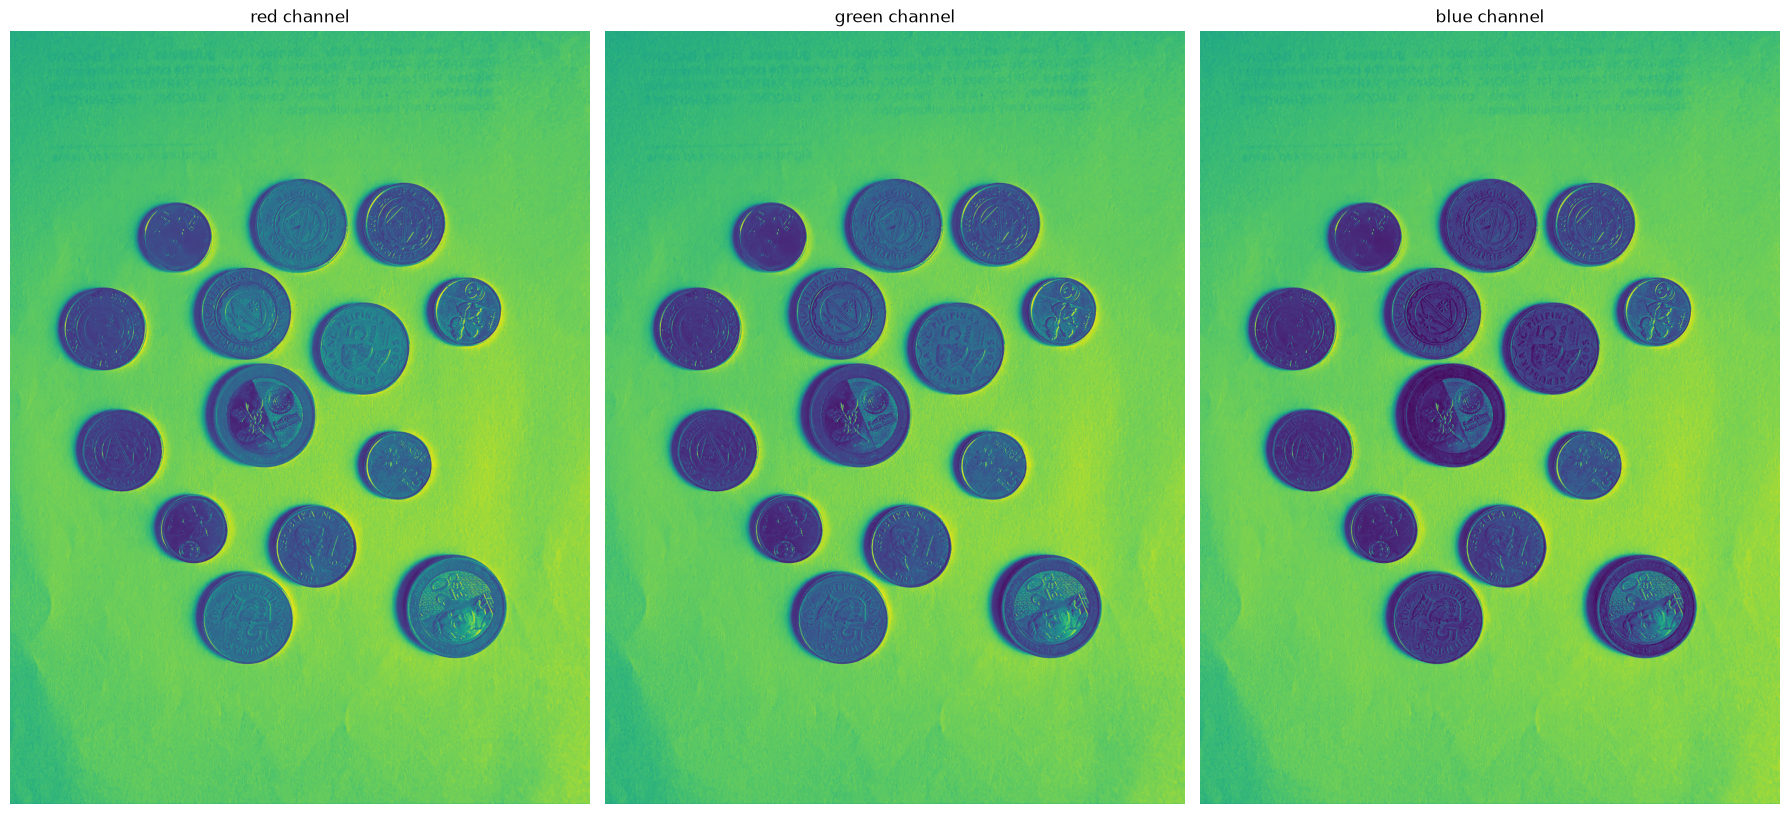

In [9]:
# Extract channels (R, G, B) in one step
rmat, gmat, bmat = cv2.split(image_rgb)
show_row([rmat, gmat, bmat], ["red channel", "green channel", "blue channel"])

Image size (h, w): (2048, 1536)


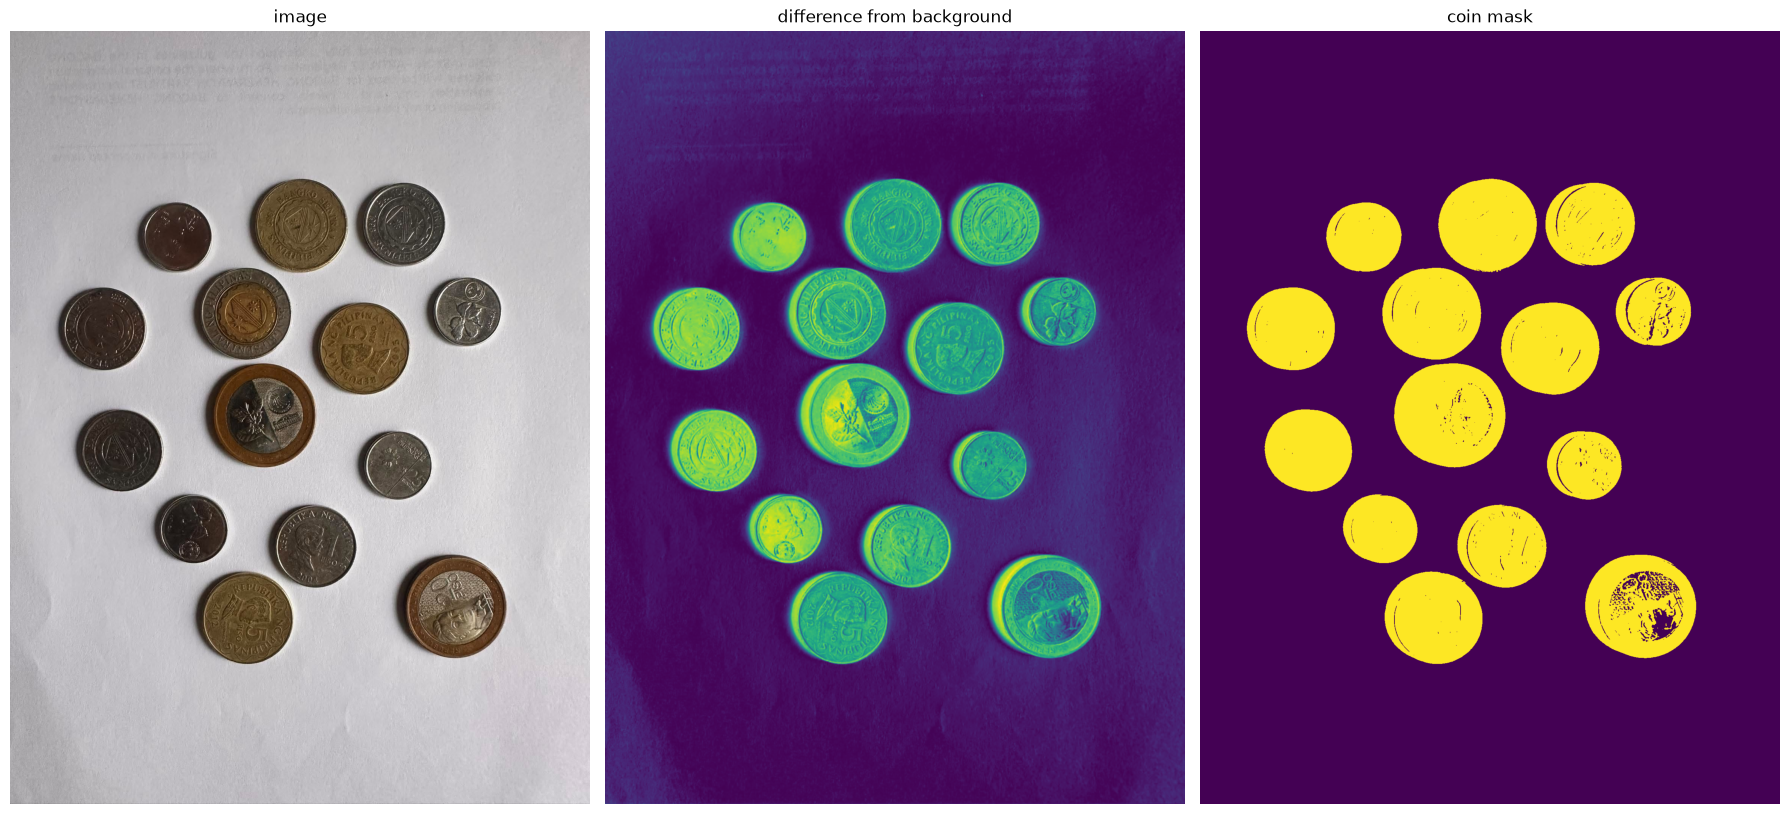

In [10]:
print("Image size (h, w):", image_rgb.shape[:2])

# Segment coins by how much each pixel differs from the background color.
# The background is estimated as the median color (coins cover only a small part of the picture),
# so this works for any background shade or lighting, not just bright backgrounds.
lab_img = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
bg = np.median(lab_img.reshape(-1, 3), axis=0)
diff = np.linalg.norm(lab_img - bg, axis=2)
diff8 = np.clip(diff / diff.max() * 255, 0, 255).astype(np.uint8)
diff8 = cv2.GaussianBlur(diff8, (5, 5), 0)

# Otsu picks the cut-off automatically
_, Icomp = cv2.threshold(diff8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # coins = 255

show_row([image_rgb, diff8, Icomp], ["image", "difference from background", "coin mask"])

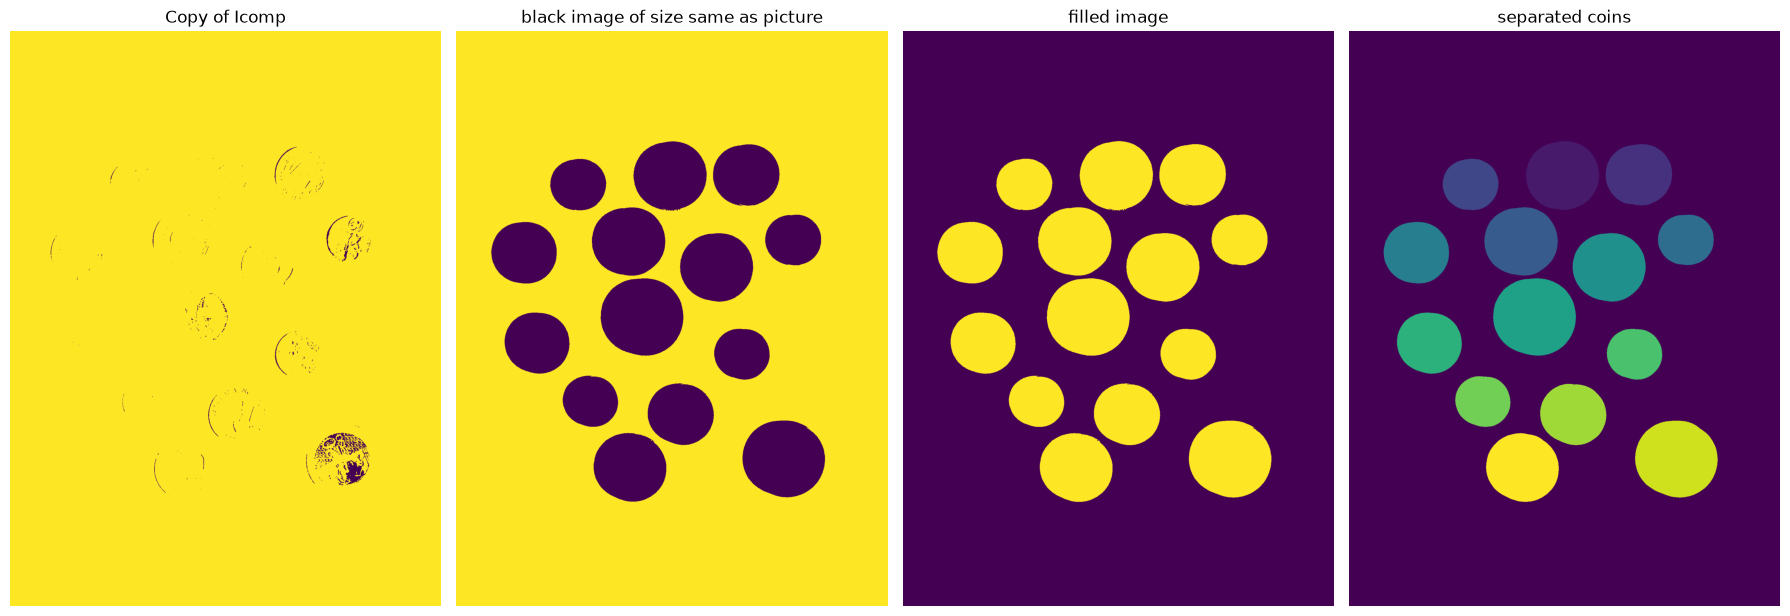

Regions found: 14
diameter = 253.4 px
diameter = 229.0 px
diameter = 191.8 px
diameter = 253.7 px
diameter = 190.8 px
diameter = 227.4 px
diameter = 253.0 px
diameter = 286.8 px
diameter = 225.2 px
diameter = 189.8 px
diameter = 189.4 px
diameter = 227.0 px
diameter = 284.0 px
diameter = 251.4 px


In [11]:
# Fill holes: flood the background from the corner, then OR in the un-flooded area
flood_fill = Icomp.copy()
h, w = flood_fill.shape
mask = np.zeros((h + 2, w + 2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 255)
filled = Icomp | cv2.bitwise_not(flood_fill)

# Morphological open (radius scales with image size; 15 px for a 324-px-wide image)
radius = max(3, round(w * 0.046))
opened = opening(filled // 255, disk(radius)).astype(np.uint8)

# Split coins that touch each other (watershed on the distance transform)
dist = ndi.distance_transform_edt(opened)
peaks = peak_local_max(dist, min_distance=max(5, round(w * 0.06)),
                       threshold_rel=0.3, labels=label(opened))
markers = np.zeros(opened.shape, dtype=int)
markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
label_image = watershed(-dist, markers, mask=opened > 0)

# Keep only real coins (ignore specks smaller than 0.3% of the image)
regions = [r for r in regionprops(label_image) if r.area >= 0.003 * h * w]

show_row([flood_fill, mask, filled, label_image],
         ["Copy of Icomp", "black image of size same as picture", "filled image", "separated coins"])

print("Regions found:", len(regions))
for region in regions:
    print(f"diameter = {2 * np.sqrt(region.area / np.pi):.1f} px")

Estimated scale: 9.73 px/mm


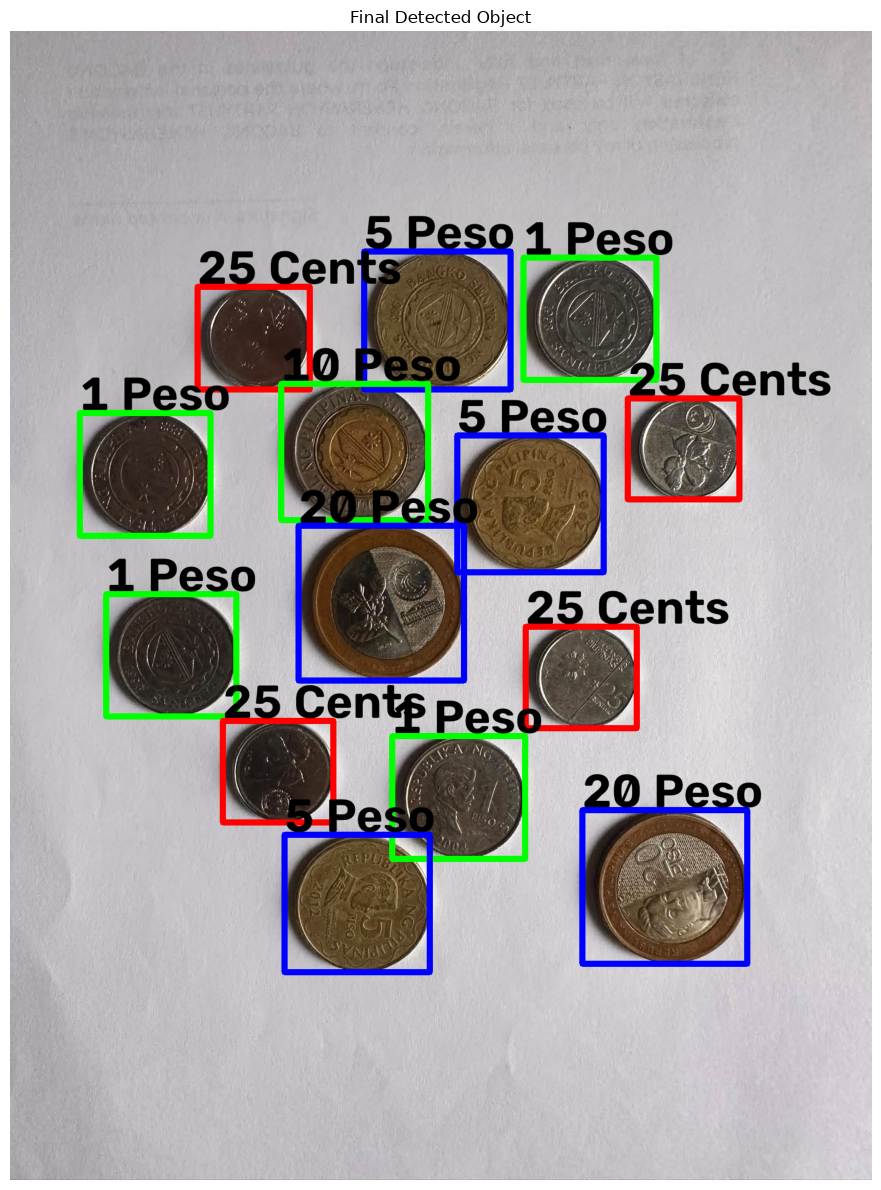

25 Cents: 4
1 Peso: 4
5 Peso: 3
10 Peso: 1
20 Peso: 2
count: 14


In [12]:
# Philippine coin sizes (mm). Sizes in pixels depend on camera distance, so the code first
# estimates the pixels-per-mm scale of the photo and then compares real-world sizes.
COIN_MM = {"25 Cents": 20.0, "1 Peso": 23.0, "5 Peso": 25.0, "10 Peso": 26.5, "20 Peso": 30.0}
BIMETAL_DELTA = 50   # ring vs center saturation difference that marks a two-metal coin
BOX_COLORS = {"25 Cents": (255, 0, 0), "1 Peso": (0, 255, 0), "5 Peso": (0, 0, 255),
              "10 Peso": (0, 255, 0), "20 Peso": (0, 0, 255)}

hsv_img = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
sat = hsv_img[:, :, 1].astype(float)
yy, xx = np.ogrid[:h, :w]


def measure(region):
    """Diameter in px, and (ring saturation - center saturation)."""
    cy, cx = region.centroid
    rad = np.sqrt(region.area / np.pi)
    dist_c = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    coin = label_image == region.label
    ring = coin & (dist_c > 0.75 * rad) & (dist_c < 0.92 * rad)
    center = coin & (dist_c < 0.5 * rad)
    return 2 * rad, sat[ring].mean() - sat[center].mean()


info = [measure(r) for r in regions]
diameters = np.array([d for d, _ in info])

# Two-metal coins are identified by color: gold ring + silver center = 20 Peso,
# silver ring + gold center = 10 Peso. Everything else is a single-metal coin.
fixed = {}
for i, (d, delta) in enumerate(info):
    if abs(delta) > BIMETAL_DELTA:
        fixed[i] = "20 Peso" if delta > 0 else "10 Peso"
single_names = ["25 Cents", "1 Peso", "5 Peso"]


def candidates(i):
    return [fixed[i]] if i in fixed else single_names


# Estimate the scale (px per mm) that best explains all coin diameters together
best_scale, best_cost = None, float("inf")
for scale_px in np.arange(1.0, 15.0, 0.01):
    cost = sum(min(abs(np.log(diameters[i] / (scale_px * COIN_MM[n]))) for n in candidates(i))
               for i in range(len(regions)))
    if cost < best_cost:
        best_scale, best_cost = scale_px, cost
print(f"Estimated scale: {best_scale:.2f} px/mm")


def classify(i):
    return min(candidates(i), key=lambda n: abs(np.log(diameters[i] / (best_scale * COIN_MM[n]))))


# Classify objects and draw boxes on a copy of the image
counts = {name: 0 for name in COIN_MM}
output_img = image_rgb.copy()
line = max(1, round(2 * w / 324))
font = max(0.5, 0.6 * w / 324)

for i, region in enumerate(regions):
    name = classify(i)
    counts[name] += 1
    minr, minc, maxr, maxc = region.bbox
    cv2.rectangle(output_img, (minc, minr), (maxc, maxr), BOX_COLORS[name], line)
    cv2.putText(output_img, name, (minc, max(15, minr - 5)), cv2.FONT_HERSHEY_SIMPLEX,
                font, (0, 0, 0), line)

# Display result
fig, ax = plt.subplots(1, 1, figsize=(18, 12))
ax.imshow(output_img)
ax.set_title("Final Detected Object")
ax.axis("off")
plt.tight_layout()
plt.show()

# Counts per denomination and overall total
for name in ["25 Cents", "1 Peso", "5 Peso", "10 Peso", "20 Peso"]:
    print(f"{name}: {counts[name]}")
print(f"count: {sum(counts.values())}")